In [ ]:
# STEP 1: Imports + download EMNIST (Kaggle)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from google.colab import files

print("Upload kaggle.json")
files.upload()
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle
!kaggle datasets download -d crawford/emnist
!unzip -q emnist.zip -d emnist_data
print("Done")

Upload kaggle.json


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/crawford/emnist
License(s): CC0-1.0
100% 1.24G/1.24G [01:09<00:00, 19.2MB/s]

Done


Train: 240000, Test: 40000, Classes: 10


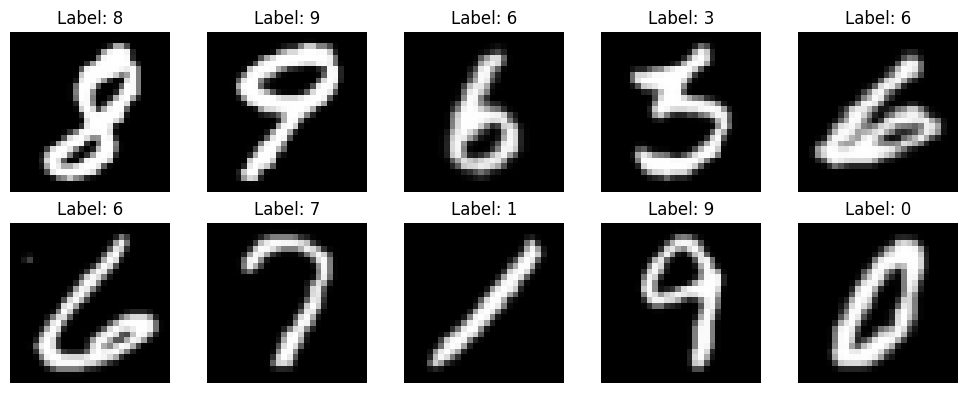

In [ ]:
# STEP 2: Load EMNIST digits
DATASET_SPLIT = 'digits'

train_data = pd.read_csv(f'emnist_data/emnist-{DATASET_SPLIT}-train.csv', header=None)
test_data = pd.read_csv(f'emnist_data/emnist-{DATASET_SPLIT}-test.csv', header=None)

y_train = train_data.iloc[:, 0].values
X_train = train_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values
X_test = test_data.iloc[:, 1:].values

img_size = 28
X_train = X_train.reshape(-1, img_size, img_size, 1)
X_test = X_test.reshape(-1, img_size, img_size, 1)

# EMNIST orientation fix
X_train = np.flip(np.rot90(X_train, k=3, axes=(1, 2)), axis=2)
X_test = np.flip(np.rot90(X_test, k=3, axes=(1, 2)), axis=2)

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

num_classes = len(np.unique(y_train))
print(f"Train: {len(X_train)}, Test: {len(X_test)}, Classes: {num_classes}")

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].squeeze(), cmap='gray')
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# STEP 3: Build tiny MLP (HLS friendly)
HIDDEN = 32

def build_tiny_model(input_shape=(28, 28, 1), num_classes=10):
    inputs = layers.Input(shape=input_shape)
    x = layers.Flatten()(inputs)
    x = layers.Dense(HIDDEN, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    return tf.keras.Model(inputs=inputs, outputs=outputs)

model = build_tiny_model(num_classes=num_classes)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 52s 12ms/step - accuracy: 0.7136 - loss: 0.8976 - val_accuracy: 0.9340 - val_loss: 0.2709 - learning_rate: 0.0010
Epoch 2/40
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 41s 11ms/step - accuracy: 0.7824 - loss: 0.7001 - val_accuracy: 0.9469 - val_loss: 0.2264 - learning_rate: 0.0010
Epoch 3/40
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 44s 12ms/step - accuracy: 0.7970 - loss: 0.6593 - val_accuracy: 0.9482 - val_loss: 0.2167 - learning_rate: 0.0010
Epoch 4/40
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 41s 11ms/step - accuracy: 0.8048 - loss: 0.6393 - val_accuracy: 0.9527 - val_loss: 0.1988 - learning_rate: 0.0010
Epoch 5/40
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 44s 12ms/step - accuracy: 0.8092 - loss: 0.6301 - val_accuracy: 0.9552 - val_loss: 0.1971 - learning_rate: 0.0010
Epoch 6/40
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 41s 11ms/step - accuracy: 0.8128 - loss: 0.6176 - val_accuracy: 0.9558 - val_loss: 0.1967 - learning_rate: 0.0010
Epoch 7/40
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 44s 12ms/step - accura

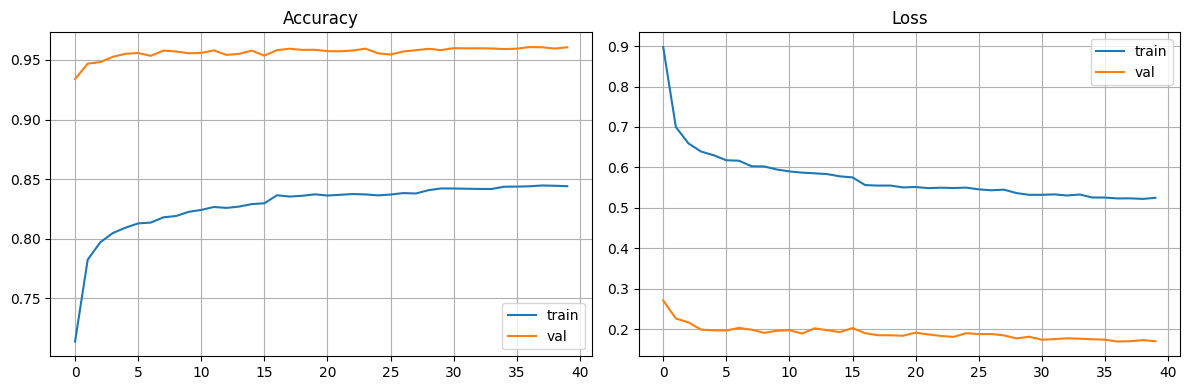

In [ ]:
# STEP 4: Train
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10),
])

def augment_data(images, labels):
    return data_augmentation(images, training=True), labels

BATCH_SIZE = 64

train_dataset = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                 .shuffle(10000).batch(BATCH_SIZE).map(augment_data).prefetch(tf.data.AUTOTUNE))
test_dataset = (tf.data.Dataset.from_tensor_slices((X_test, y_test))
                .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7, verbose=1),
]

history = model.fit(train_dataset, validation_data=test_dataset, epochs=40, callbacks=callbacks, verbose=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history['accuracy'], label='train')
ax1.plot(history.history['val_accuracy'], label='val')
ax1.set_title('Accuracy'); ax1.legend(); ax1.grid(True)
ax2.plot(history.history['loss'], label='train')
ax2.plot(history.history['val_loss'], label='val')
ax2.set_title('Loss'); ax2.legend(); ax2.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 5: Evaluate float model
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Float test accuracy: {test_acc:.4f}")

Float test accuracy: 0.9608


In [ ]:
# STEP 6: Quantize to int8 + export for HLS
N_TEST = 1000  # images sent to FPGA

dense = [l for l in model.layers if isinstance(l, layers.Dense)]
W1, b1 = dense[0].get_weights(); W1 = W1.T   # (H, 784)
W2, b2 = dense[1].get_weights(); W2 = W2.T   # (10, H)
H = W1.shape[0]

Xu8 = np.round(X_test.reshape(-1, 784) * 255).astype(np.uint8)

s1 = np.abs(W1).max() / 127
s2 = np.abs(W2).max() / 127
q1 = np.round(W1 / s1).astype(np.int8)
q2 = np.round(W2 / s2).astype(np.int8)
b1q = np.round(b1 * 255 / s1).astype(np.int32)

# calibrate hidden shift
h = np.maximum(Xu8[:2000].astype(np.int32) @ q1.T.astype(np.int32) + b1q, 0)
SHIFT = max(0, int(np.ceil(np.log2(h.max() / 127))))
s_h = (s1 / 255) * (2 ** SHIFT)
b2q = np.round(b2 / (s2 * s_h)).astype(np.int32)

# integer reference model (HLS must match this exactly)
def infer(X):
    h = np.maximum(X.astype(np.int32) @ q1.T.astype(np.int32) + b1q, 0)
    h8 = np.minimum(h >> SHIFT, 127)
    return (h8 @ q2.T.astype(np.int32) + b2q).argmax(1)

pred = infer(Xu8)
print(f"Float acc:                {test_acc:.4f}")
print(f"Int8 acc (full test set): {(pred == y_test).mean():.4f}   SHIFT={SHIFT}")
print(f"Int8 acc (first {N_TEST}):    {(pred[:N_TEST] == y_test[:N_TEST]).mean():.4f}")

def arr(name, a, t):
    return f"static const {t} {name}[{a.size}] = {{{','.join(str(v) for v in a.flatten())}}};\n"

with open("weights.h", "w") as f:
    f.write("#pragma once\n")
    f.write(f"#define N_IN 784\n#define N_HID {H}\n#define N_OUT 10\n#define SHIFT {SHIFT}\n")
    f.write(arr("W1", q1, "signed char"))
    f.write(arr("B1", b1q, "int"))
    f.write(arr("W2", q2, "signed char"))
    f.write(arr("B2", b2q, "int"))

with open("test_set.bin", "wb") as f:
    f.write(Xu8[:N_TEST].tobytes())
    f.write(y_test[:N_TEST].astype(np.uint8).tobytes())

files.download("weights.h")
files.download("test_set.bin")

Float acc:                0.9608
Int8 acc (full test set): 0.9618   SHIFT=12
Int8 acc (first 1000):    0.9550


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>